# 02 – Data Exploration

## 1. Goal
Get to know the data of the two control municipalities before building the detection tool:
- What do the sonnendach.ch roof surfaces look like (number, size, suitability)?
- How many buildings already have a PV plant according to the BFE register?
- Are PV plants visible on the SWISSIMAGE aerial images?

## 2. Inputs / Outputs
| | |
| --- | --- |
| **Inputs** | `data/interim/roofs_*.gpkg`, `data/interim/pv_register_*.gpkg`, `data/raw/swissimage_*/*.tif` (from notebook 01) |
| **Outputs** | none (only figures and numbers in this notebook) |

In [1]:
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
import rasterio

In [3]:
roofs_uznach = gpd.read_file("../data/interim/roofs_uznach.gpkg")
roofs_pully = gpd.read_file("../data/interim/roofs_pully.gpkg")
pv_uznach = gpd.read_file("../data/interim/pv_register_uznach.gpkg")
pv_pully = gpd.read_file("../data/interim/pv_register_pully.gpkg")
print("Data loaded")

Data loaded


## 3. Analysis
### 3.1 Roof surfaces
A building usually has several roof surfaces. `KLASSE` is the suitability class from sonnendach.ch:
1 = low, 2 = medium, 3 = good, 4 = very good, 5 = excellent.

In [4]:
print("Uznach:", len(roofs_uznach), "roof surfaces on", roofs_uznach["GWR_EGID"].nunique(), "buildings")
print("Pully: ", len(roofs_pully), "roof surfaces on", roofs_pully["GWR_EGID"].nunique(), "buildings")

print("\nRoof area in m2")
print(pd.DataFrame({"Uznach": roofs_uznach["FLAECHE"].describe(), "Pully": roofs_pully["FLAECHE"].describe()}).round(1))

Uznach: 6183 roof surfaces on 1276 buildings
Pully:  11857 roof surfaces on 2382 buildings

Roof area in m2
       Uznach    Pully
count  6183.0  11857.0
mean     76.0     57.0
std     187.9     86.1
min       0.0      0.0
25%      17.5     14.3
50%      44.7     35.0
75%      84.4     69.6
max    8551.6   2316.3


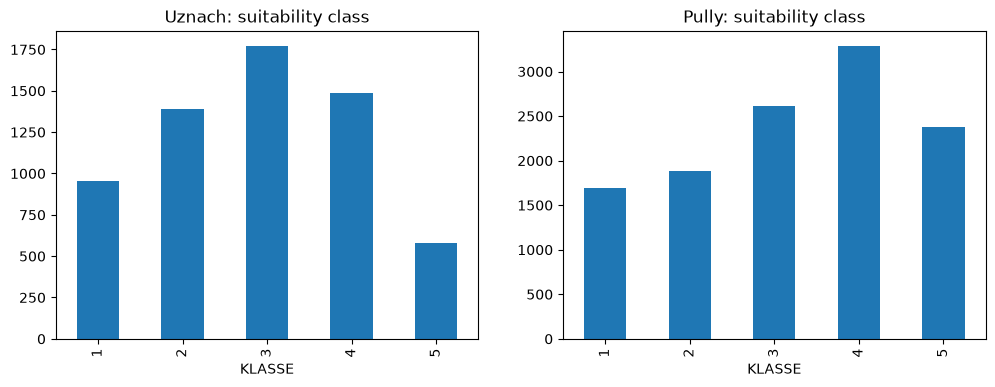

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

roofs_uznach["KLASSE"].value_counts().sort_index().plot.bar(ax=axes[0])
axes[0].set_title("Uznach: suitability class")

roofs_pully["KLASSE"].value_counts().sort_index().plot.bar(ax=axes[1])
axes[1].set_title("Pully: suitability class")

plt.show()

**Observation:** _comment on output_

### 3.2 PV plants in the BFE register
The aerial images were taken in 2025 (Uznach) and 2023 (Pully). Plants built after the flight can't be seen on the images.

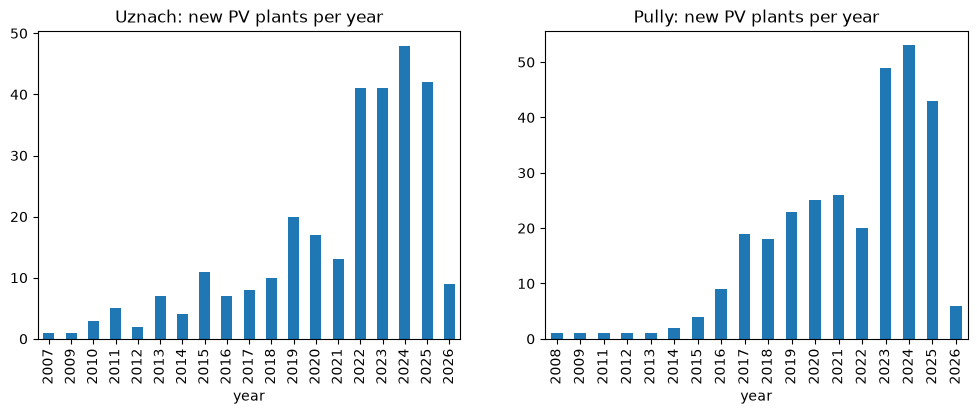

In [6]:
pv_uznach["year"] = pd.to_datetime(pv_uznach["BeginningOfOperation"]).dt.year
pv_pully["year"] = pd.to_datetime(pv_pully["BeginningOfOperation"]).dt.year

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

pv_uznach["year"].value_counts().sort_index().plot.bar(ax=axes[0])
axes[0].set_title("Uznach: new PV plants per year")

pv_pully["year"].value_counts().sort_index().plot.bar(ax=axes[1])
axes[1].set_title("Pully: new PV plants per year")

plt.show()

In [7]:
print("Uznach: plants built after the flight (2025):", (pv_uznach["year"] > 2025).sum(), "of", len(pv_uznach))
print("Pully:  plants built after the flight (2023):", (pv_pully["year"] > 2023).sum(), "of", len(pv_pully))

Uznach: plants built after the flight (2025): 9 of 290
Pully:  plants built after the flight (2023): 102 of 302


**Observation:** Uznach is not going to pose a problem, while in Pully more than a third of all plants have been built after the flight. We need to define a cutoff date, else it is going to pose problems

### 3.3 Linking roofs and register
Both datasets contain the federal building ID (EGID). With it we can mark every roof surface whose building has a PV plant in the register.

In [8]:
roofs_uznach["has_pv"] = roofs_uznach["GWR_EGID"].isin(pv_uznach["EGID"])
roofs_pully["has_pv"] = roofs_pully["GWR_EGID"].isin(pv_pully["EGID"])

buildings_uznach = roofs_uznach.groupby("GWR_EGID")["has_pv"].max()
buildings_pully = roofs_pully.groupby("GWR_EGID")["has_pv"].max()

print("Uznach:", buildings_uznach.sum(), "of", len(buildings_uznach), "buildings have PV ->", round(buildings_uznach.mean() * 100, 1), "%")
print("Pully: ", buildings_pully.sum(), "of", len(buildings_pully), "buildings have PV ->", round(buildings_pully.mean() * 100, 1), "%")

Uznach: 228 of 1276 buildings have PV -> 17.9 %
Pully:  208 of 2382 buildings have PV -> 8.7 %


In [9]:
pv_uznach["in_sonnendach"] = pv_uznach["EGID"].isin(roofs_uznach["GWR_EGID"])
pv_pully["in_sonnendach"] = pv_pully["EGID"].isin(roofs_pully["GWR_EGID"])

print("Register plants whose EGID is not found in sonnendach:")
print("Uznach:", (pv_uznach["in_sonnendach"] == False).sum(), "of", len(pv_uznach))
print("Pully: ", (pv_pully["in_sonnendach"] == False).sum(), "of", len(pv_pully))

Register plants whose EGID is not found in sonnendach:
Uznach: 56 of 290
Pully:  86 of 302


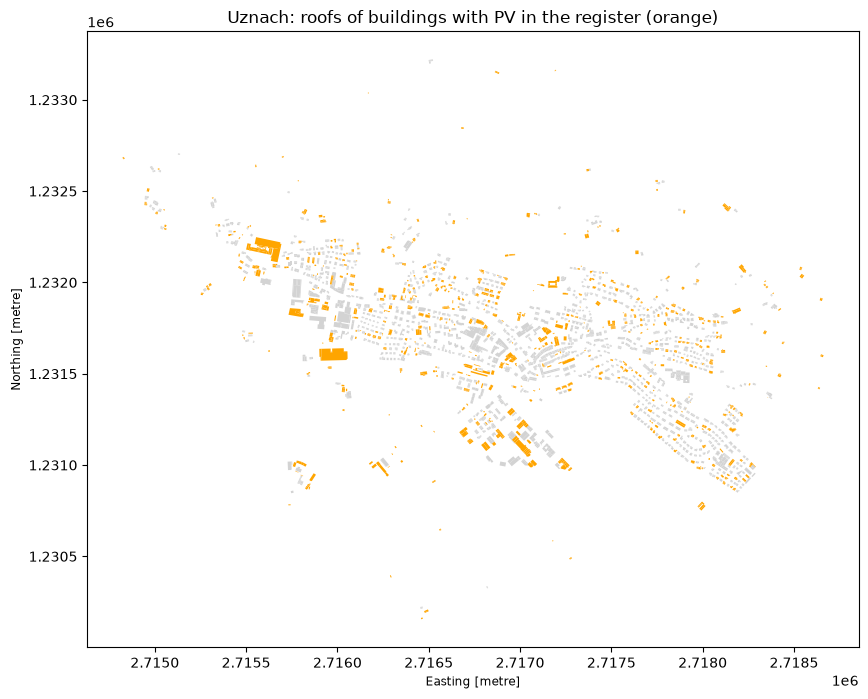

In [10]:
fig, ax = plt.subplots(figsize=(10, 8))
roofs_uznach[roofs_uznach["has_pv"] == False].plot(ax=ax, color="lightgrey")
roofs_uznach[roofs_uznach["has_pv"] == True].plot(ax=ax, color="orange")
ax.set_title("Uznach: roofs of buildings with PV in the register (orange)")
plt.show()

**Observation:** Why this difference ? Data Quality Issue? Check sonnendach.ch documentation. Maybe difference in years since last aerial?

### 3.4 Look at single buildings on the aerial images
The function cuts out one building from the SWISSIMAGE tile and draws the sonnendach roof surfaces in red.
The tile is found with the centre of the building (tile name = lower left corner in km).
If a building lies on the edge of a tile, the part outside of the tile is shown in black.

In [11]:
def show_building(roofs, egid, folder, year, title):
    building = roofs[roofs["GWR_EGID"] == egid]
    xmin, ymin, xmax, ymax = building.total_bounds
    xmin, ymin, xmax, ymax = xmin - 10, ymin - 10, xmax + 10, ymax + 10   # 10 m border

    centre = building.union_all().centroid
    e = int(centre.x // 1000)
    n = int(centre.y // 1000)
    src = rasterio.open(f"{folder}/swissimage-dop10_{year}_{e}-{n}.tif")

    window = src.window(xmin, ymin, xmax, ymax)
    image = src.read(window=window, boundless=True)

    fig, ax = plt.subplots(figsize=(6, 6))
    ax.imshow(image.transpose(1, 2, 0), extent=[xmin, xmax, ymin, ymax])
    building.boundary.plot(ax=ax, color="red", linewidth=1)
    ax.set_title(title)
    ax.axis("off")
    plt.show()

Biggest PV plant in each municipality (built before the flight and found in sonnendach, should be clearly visible):

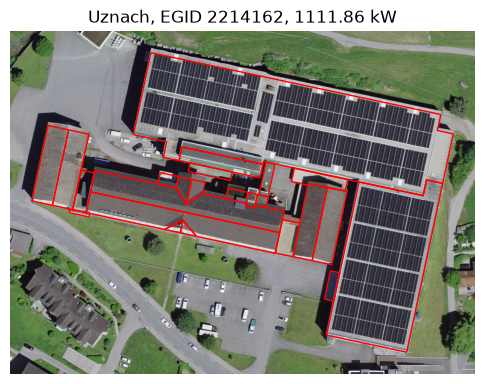

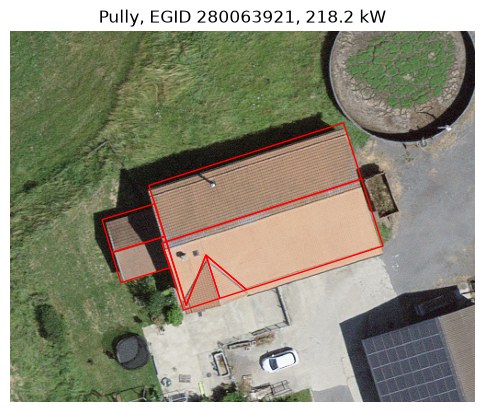

In [12]:
pv_visible = pv_uznach[(pv_uznach["year"] <= 2025) & pv_uznach["in_sonnendach"]].sort_values("TotalPower", ascending=False)
egid = pv_visible["EGID"].iloc[0]
show_building(roofs_uznach, egid, "../data/raw/swissimage_uznach", 2025, f"Uznach, EGID {int(egid)}, {pv_visible['TotalPower'].iloc[0]} kW")

pv_visible = pv_pully[(pv_pully["year"] <= 2023) & pv_pully["in_sonnendach"]].sort_values("TotalPower", ascending=False)
egid = pv_visible["EGID"].iloc[0]
show_building(roofs_pully, egid, "../data/raw/swissimage_pully", 2023, f"Pully, EGID {int(egid)}, {pv_visible['TotalPower'].iloc[0]} kW")

A small PV plant (typical single-family house, around 10 kW):

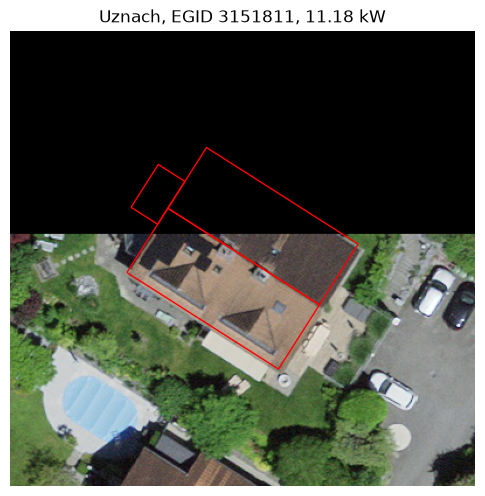

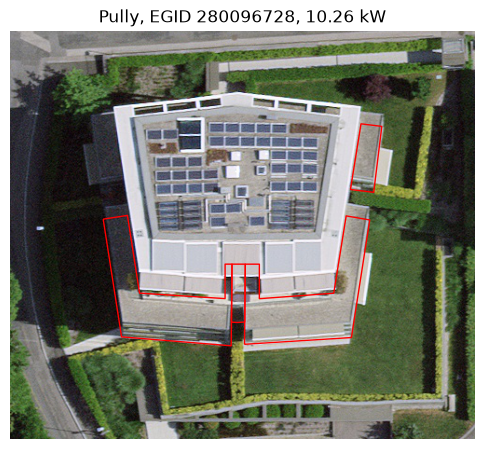

In [13]:
small = pv_uznach[(pv_uznach["year"] <= 2025) & pv_uznach["in_sonnendach"] & (pv_uznach["TotalPower"] < 12) & (pv_uznach["TotalPower"] > 8)]
egid = small["EGID"].iloc[0]
show_building(roofs_uznach, egid, "../data/raw/swissimage_uznach", 2025, f"Uznach, EGID {int(egid)}, {small['TotalPower'].iloc[0]} kW")

small = pv_pully[(pv_pully["year"] <= 2023) & pv_pully["in_sonnendach"] & (pv_pully["TotalPower"] < 12) & (pv_pully["TotalPower"] > 8)]
egid = small["EGID"].iloc[0]
show_building(roofs_pully, egid, "../data/raw/swissimage_pully", 2023, f"Pully, EGID {int(egid)}, {small['TotalPower'].iloc[0]} kW")

A very well suited roof (class 5) without PV in the register:

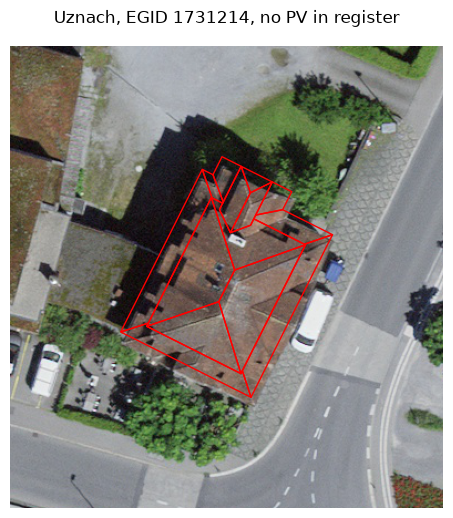

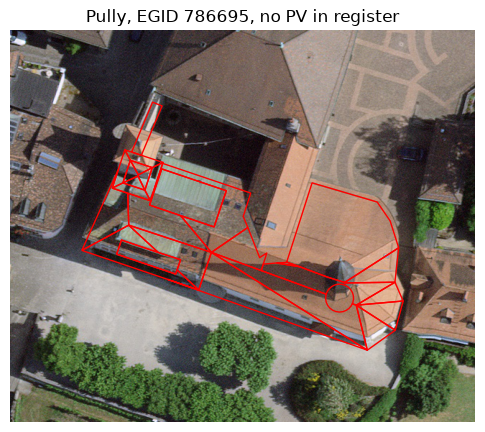

In [14]:
no_pv = roofs_uznach[(roofs_uznach["has_pv"] == False) & (roofs_uznach["KLASSE"] == 5)]
egid = no_pv["GWR_EGID"].sample(1, random_state=1).iloc[0]
show_building(roofs_uznach, egid, "../data/raw/swissimage_uznach", 2025, f"Uznach, EGID {int(egid)}, no PV in register")

no_pv = roofs_pully[(roofs_pully["has_pv"] == False) & (roofs_pully["KLASSE"] == 5)]
egid = no_pv["GWR_EGID"].sample(1, random_state=1).iloc[0]
show_building(roofs_pully, egid, "../data/raw/swissimage_pully", 2023, f"Pully, EGID {int(egid)}, no PV in register")

**Observation:** The roofs are very good documented and red lines match it very well. But it seems that sometimes the Id doesn't match the correct roof. Biggest plant in Pully is on roof in adjacent building. Probably an issue if model gets wrong labels...
Small plants are clearly visible and easy to detect. In Uznach the building is at the border of the picture and therefore half of it is black. 

## 4. Conclusion & Open Points
- _summary_